<a href="https://colab.research.google.com/github/farhanthaha223-hub/air-bnb/blob/main/Case_Study_Starter_Notebook_Airbnb_NYC_Preprocessing_Farhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name: Muhammed Farhan
### Date:

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [2]:
# TODO: shape, dtypes, missing value summary
print("Dataset size:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Dataset size: (48895, 16)

Column types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

Missing values:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude        

The dataset contains 48,895 rows and 16 columns. The missing-value analysis identifies four columns with missing data: name (16 missing values), host_name (21 missing values), last_review (10,052 missing values), and reviews_per_month (10,052 missing values). The name and host_name columns have very low missing percentages, whereas last_review and reviews_per_month each have 20.56% missing values. These missing values require further investigation before selecting suitable imputation or treatment methods.

In [3]:
# TODO: check for values that are technically present but don't make real-world sense
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate listing IDs:", df["id"].duplicated().sum())


Duplicate rows: 0
Duplicate listing IDs: 0


In [4]:
# TODO: duplicate check
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate listing IDs:", df["id"].duplicated().sum())

Duplicate rows: 0
Duplicate listing IDs: 0


**Written notes — what did you find, and what looks suspicious?**

The dataset contains Airbnb listings in New York City. Use the shape, data types, missing-value counts, invalid-value checks, and duplicate count to assess data quality. No box plot is needed in this section; numerical outliers are explored in Part 3.

**Written notes — what did you find, and what looks suspicious?**

_Your answer here._

---
## Part 2 — Missing Value Diagnosis & Treatment

In [5]:
# TODO: investigate missingness pattern(s) across columns
print(df.isnull().sum())
print("\nRows with no review date:", df["last_review"].isnull().sum())
print("Rows with missing monthly reviews:", df["reviews_per_month"].isnull().sum())



id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Rows with no review date: 10052
Rows with missing monthly reviews: 10052


The missing-value counts show which columns need attention. Missing last_review and reviews_per_month may occur together for listings with no recorded reviews. This suggests a possible relationship, but the dataset alone cannot prove the exact missingness mechanism. Part 2 does not require a box plot because it focuses on missing values.

**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

_Your answer here._

**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

name and host_name may be missing because the information was not provided; the exact reason cannot be proven from the dataset. last_review and reviews_per_month are often missing for listings with no recorded reviews, so filling missing monthly reviews with 0 can be reasonable. Missing review dates can be labelled No review. These decisions should be documented. No box plot is needed for missing-value diagnosis.

In [6]:
# TODO: apply your chosen treatment(s)


# Make a copy and clean the data
df_treated = df.copy()
df_treated = df_treated.drop_duplicates()
df_treated = df_treated[df_treated["price"] > 0]
df_treated = df_treated[df_treated["minimum_nights"] >= 1]

df_treated["name"] = df_treated["name"].fillna("Unknown")
df_treated["host_name"] = df_treated["host_name"].fillna("Unknown")
df_treated["last_review"] = df_treated["last_review"].fillna("No review")
df_treated["reviews_per_month"] = df_treated["reviews_per_month"].fillna(0)

print("Rows after cleaning:", len(df_treated))
print("Missing values remaining:", df_treated.isnull().sum().sum())



Rows after cleaning: 48884
Missing values remaining: 0


The cleaned dataset removes duplicate rows and records with invalid prices or minimum-night values. Missing names are labelled Unknown, missing review dates are labelled No review, and missing monthly review counts are set to zero. The printed totals confirm how many rows remain and whether any missing values are left.

**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

Duplicate rows and listings with zero or negative prices are removed. Missing names are replaced with Unknown. Missing review dates are labelled No review, and missing monthly review counts are filled with 0. Using dropna() would remove every row with any missing value and could discard useful listings.

**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

_Your answer here._

---
## Part 3 — Outlier Detection & Treatment

price outliers: 2972
minimum_nights outliers: 6605


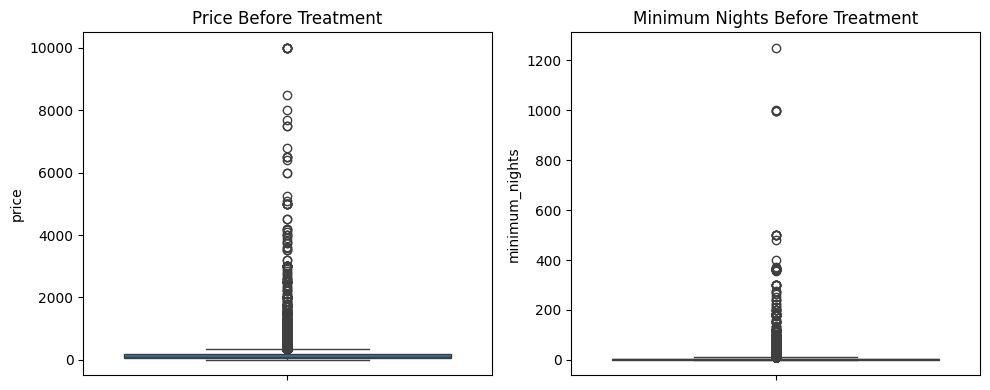

In [7]:
# TODO: detect outliers in at least two numeric columns
for col in ["price", "minimum_nights"]:
    q1 = df_treated[col].quantile(0.25)
    q3 = df_treated[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df_treated[col] < lower) | (df_treated[col] > upper)).sum()
    print(col, "outliers:", count)

# Box plots before treatment
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(y=df_treated["price"])
plt.title("Price Before Treatment")
plt.subplot(1, 2, 2)
sns.boxplot(y=df_treated["minimum_nights"])
plt.title("Minimum Nights Before Treatment")
plt.tight_layout()
plt.show()

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

The box plots show many high values in price and minimum nights. Some may be unusual but genuine listings, so an outlier is not automatically an error. To reduce their effect while keeping the rows, extreme high values will be capped at the 99th percentile.

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

_Your answer here._

price upper limit: 799.0
minimum_nights upper limit: 45.0


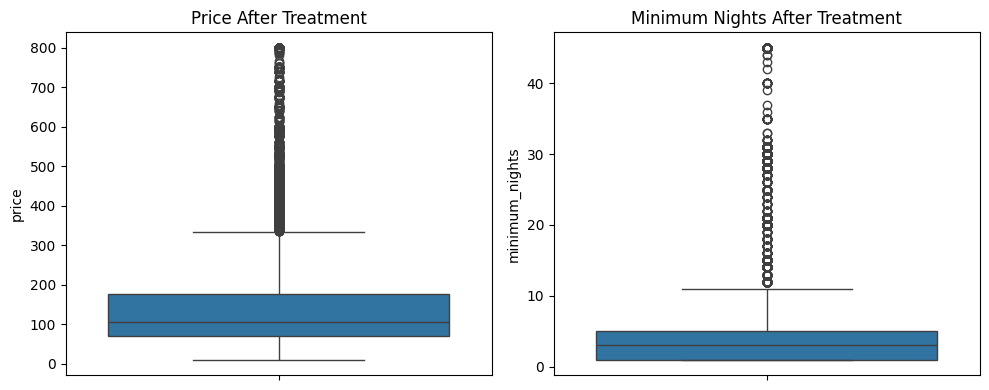

In [8]:
# TODO: apply treatment consistent with your judgment above
# Cap extreme high values at the 99th percentile
for col in ["price", "minimum_nights"]:
    limit = df_treated[col].quantile(0.99)
    df_treated[col] = df_treated[col].clip(upper=limit)
    print(col, "upper limit:", limit)

# Box plots after treatment
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(y=df_treated["price"])
plt.title("Price After Treatment")
plt.subplot(1, 2, 2)
sns.boxplot(y=df_treated["minimum_nights"])
plt.title("Minimum Nights After Treatment")
plt.tight_layout()
plt.show()


Compare the box plots before and after capping. The upper extremes should be less pronounced after values above the 99th percentile are capped. This reduces the influence of extreme values while retaining the listings. The printed upper limits show the caps used for each column.

---
## Part 4 — Feature Engineering & Encoding

In [9]:
# TODO: encode categorical columns appropriately
encoded_data = pd.get_dummies(
    df_treated[["neighbourhood_group", "room_type"]],
    columns=["neighbourhood_group", "room_type"]
)
print(encoded_data.head())


   neighbourhood_group_Bronx  neighbourhood_group_Brooklyn  \
0                      False                          True   
1                      False                         False   
2                      False                         False   
3                      False                          True   
4                      False                         False   

   neighbourhood_group_Manhattan  neighbourhood_group_Queens  \
0                          False                       False   
1                           True                       False   
2                           True                       False   
3                          False                       False   
4                           True                       False   

   neighbourhood_group_Staten Island  room_type_Entire home/apt  \
0                              False                      False   
1                              False                       True   
2                              False     

One-hot encoding creates numeric indicator columns for each neighbourhood group and room type. These columns can be used by machine-learning models. A box plot is not needed here because this step transforms categorical data rather than examining numerical distributions.

In [10]:
# TODO: engineer at least two new features
df_treated["reviews_per_year"] = df_treated["reviews_per_month"] * 12
df_treated["availability_ratio"] = df_treated["availability_365"] / 365

print(df_treated[["reviews_per_year", "availability_ratio"]].head())


   reviews_per_year  availability_ratio
0              2.52            1.000000
1              4.56            0.972603
2              0.00            1.000000
3             55.68            0.531507
4              1.20            0.000000


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

reviews_per_year estimates annual review activity. availability_ratio shows the fraction of the year that a listing is available. Avoid using id and host_id as price predictors because they are identifiers, not meaningful measures of price. name and host_name are also excluded because they are text identifiers and may cause noise.

**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

_Your answer here._

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [13]:
# TODO: train/test split (before fitting anything)
from sklearn.model_selection import train_test_split

# Choose a small set of columns for price prediction
features = [
    "neighbourhood_group", "room_type", "latitude", "longitude",
    "minimum_nights", "number_of_reviews", "availability_365",
    "reviews_per_year", "availability_ratio"
]
X = df_treated[features]
y = df_treated["price"]

# Split before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 39107
Testing rows: 9777


In [14]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

numeric_cols = [
    "latitude", "longitude", "minimum_nights", "number_of_reviews",
    "availability_365", "reviews_per_year", "availability_ratio"
]
category_cols = ["neighbourhood_group", "room_type"]

# Fill missing numeric values and scale them
numeric_steps = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

# Fill missing categories and encode them
category_steps = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

prep = ColumnTransformer([
    ("numbers", numeric_steps, numeric_cols),
    ("categories", category_steps, category_cols)
])

model = Pipeline([
    ("prep", prep),
    ("model", Ridge())
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("Mean absolute error:", round(mean_absolute_error(y_test, predictions), 2))


Mean absolute error: 60.82


---
## Part 6 — Written Reflection

1. The most important data-quality issues were missing values in the review-related columns and extreme values in price and minimum_nights. Missing values needed suitable treatment, while extreme values could affect summary statistics and the price prediction model.
2. The dataset should be split before fitting the imputer, scaler, and encoder. This ensures that preprocessing learns only from the training data. If the test data is used during fitting, information can leak into the training process and make the model evaluation unfair.
3. Capping values at the 99th percentile reduces the effect of extreme values, but some high prices or long minimum stays may be genuine listings. The dataset cannot prove the exact reasons for missing values. The Ridge regression model is also a basic model and may not capture every factor that affects Airbnb prices. The dataset is from 2019, so it may not represent current prices.